# S&P 500 Long-short Strategy

This notebook presents feature analysis, feature importance analysis, and deduplication. Then, three consecutive models are trained: a linear Ridge model with L2 regularization, a LightGBM model with manually chosen parameters, and a LightGBM model with parameters optimised via Optuna within the nested walk-forward procedure. A comparison of predictive power and signal stability is provided.

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import time
import lightgbm as lgb
from sklearn.linear_model import Ridge
import statsmodels.api as sm

## Feature Analysis and Deduplication

Split the whole panel into two subsets: one for **research and validation**, and one for a **holdout** period. The holdout period is not used for research or making any strategy/design desicions and reserved only for the final testing of the algorithm's performance. A gap of H+1 days is left before the holdout period to prevent leakage caused by label overlap between the research labels and the holdout information. This is called **purging**.

In [2]:
# Fixed label horizon
H = 5

# Set the configuration to display full tables via print
pl.Config.set_tbl_cols(20)

# Start of the holdout test period
Holdout_start = pl.date(2024, 1, 1)

panel = pl.read_parquet("panel.parquet")
feature_cols = [col for col in panel.columns if col.endswith("_rank")]

# Extract a calendar of trading days used for research
dates_research = (
    panel
    .filter(pl.col("Date") < Holdout_start)
    .select(pl.col("Date"))
    .to_series()
    .unique()
    .sort()
)

# Restrict the data to the research set
panel_research = panel.filter(pl.col("Date").is_in(dates_research[:-(H + 1)].implode()))

Check the predictive power of single-factor models using the **Information Coefficient (IC)** as a metric. To do this, we compute the daily IC for all feature-target pairs. Later, we will compare this metric with the IC of the final LightGBM model.

In [3]:
def daily_IC(data, cols, target="Future_return"):
    single_factor_IC = []
    for col in cols:
        mask = pl.col(col).is_not_null() & pl.col(target).is_not_null()
        single_factor_IC.append(pl.corr(pl.col(col).filter(mask), pl.col(target).filter(mask), method="spearman").alias(col))
    return data.group_by("Date").agg(single_factor_IC).sort("Date")

IC = daily_IC(panel_research, feature_cols)        

Look at the mean values of the IC for each feature-target pair over the research period:

In [4]:
IC.mean()

Date,Mom_12_1_rank,Mom_6_1_rank,Mom_3_1_rank,Rev_21d_rank,Rev_5d_rank,Mom_12_1_RA_rank,RV_21_rank,RV_63_rank,GK_21_rank,GK_63_rank,RV_ratio_rank,GK_ratio_rank,Beta_63_rank,Beta_252_rank,IVOL_63_rank,IVOL_252_rank,Skew_21_rank,Max_21_rank
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2011-12-28 18:43:52.399270,0.010007,0.003737,-0.0037,-0.011723,-0.018504,0.009394,-0.000461,-0.000076,-0.00056,-0.000423,-0.001572,-0.001817,0.000547,0.001038,-0.000869,-0.000334,0.001808,-0.001775


There are no suspiciously high values suggesting that there is no leakage.

We further investigate the single-factor ICs to better understand the features' predictive power. To do this, we calculate yearly ICs for all features and analyse their stability over time through sign consistency.

In [5]:
IC_yearly = (
    IC.group_by(pl.col("Date").dt.year().alias("Year"))
    .agg(pl.col(feature_cols).mean())
    .sort("Year")
)

stability = IC_yearly.select(
    (pl.col(col).sign() == pl.col(col).mean().sign()).mean().alias(col)
    for col in feature_cols
).transpose(include_header=True, header_name="Feature", column_names=["Sign_consistency"])

In [6]:
IC_yearly

Year,Mom_12_1_rank,Mom_6_1_rank,Mom_3_1_rank,Rev_21d_rank,Rev_5d_rank,Mom_12_1_RA_rank,RV_21_rank,RV_63_rank,GK_21_rank,GK_63_rank,RV_ratio_rank,GK_ratio_rank,Beta_63_rank,Beta_252_rank,IVOL_63_rank,IVOL_252_rank,Skew_21_rank,Max_21_rank
i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2000,-0.001465,0.018891,0.00847,-0.0303,-0.032747,-0.002161,-0.018379,-0.015998,-0.019266,-0.021079,-0.015285,-0.004257,0.008021,-0.001331,-0.018235,-0.022782,0.008912,-0.019523
2001,0.010014,-0.016513,-0.026614,-0.031096,-0.035162,0.012498,-0.002163,-0.00073,0.005738,0.002726,-0.010432,0.009369,0.001062,-0.008011,-0.001621,-0.010828,0.013081,-0.003605
2002,0.033246,-0.004771,-0.001574,-0.040121,-0.041377,0.035602,-0.025552,-0.023981,-0.013833,-0.019871,0.011829,0.020123,-0.042065,-0.053791,-0.014952,-0.023146,-0.022936,-0.036233
2003,-0.018595,0.008673,-0.03413,-0.009164,-0.020102,-0.019707,0.052501,0.059824,0.055668,0.057781,-0.006823,-0.013868,0.040595,0.043747,0.054107,0.054234,0.012356,0.044705
2004,0.001754,-0.000347,-0.01077,-0.007048,-0.021769,0.005964,-0.001552,0.005623,-0.000529,0.002777,-0.020944,-0.010988,0.005651,-0.00991,0.004396,0.004708,0.003149,-0.001903
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2019,0.004497,-0.010679,0.005663,-0.049157,-0.002827,0.003235,0.015914,0.006442,0.007256,-0.000111,0.027668,0.028915,0.008173,0.014141,-0.004072,-0.008337,-0.011333,0.004133
2020,0.023891,0.006643,-0.001665,0.002884,-0.036534,0.028542,-0.011753,-0.002455,-0.007825,-0.002182,0.01514,-0.006551,-0.012201,-0.001168,0.001753,-0.006111,0.020803,-0.00143
2021,-0.035742,-0.023906,-0.024788,-0.010531,-0.012833,-0.023114,-0.000102,-0.000852,-0.006493,-0.007126,-0.013401,0.002853,0.025213,0.025392,-0.010075,-0.006234,-0.006304,-0.011083


In [7]:
stability.sort("Sign_consistency")

Feature,Sign_consistency
str,f64
"""Mom_6_1_rank""",0.458333
"""Beta_252_rank""",0.5
"""Beta_63_rank""",0.541667
"""IVOL_252_rank""",0.541667
"""RV_63_rank""",0.583333
…,…
"""Mom_12_1_RA_rank""",0.708333
"""Skew_21_rank""",0.708333
"""Mom_12_1_rank""",0.75


## Walk-forward cross validation

We run **walk-forward cross-validation** to assess the model stability over time and to observe how the target's predictions respond to features across different periods. We use an **expanding training window**, and the testing period is always 1 year. A margin of H+1 days is left at the end of each training period before the testing period as part of the **purging procedure**. This removes the overlap between training labels and information available in the testing set, eliminating **look-ahead bias**.

In [8]:
def make_folds(dates, first_test_year=2005):
    folds = []
    for year in range(first_test_year, dates.max().year + 1):
        test_dates = dates.filter(dates.dt.year() == year)
        train_dates = dates.filter(dates < test_dates[0])[:-(H+1)]
        folds.append((year, train_dates, test_dates))
    return folds

folds = make_folds(dates_research) 

## Linear model - Ridge

First, we build a linear regression model with L2 regularization - Ridge. Later we compare its predictive power with that of LightGBM to demonstrate the adantage of the boosting model over the linear model.

In [9]:
%%time
ridge_predictions = []

for year, train_dates, test_dates in folds:
    train = panel_research.filter(pl.col("Date").is_in(train_dates.implode()) & pl.col("Target").is_not_null())
    test = panel_research.filter(pl.col("Date").is_in(test_dates.implode()))
    model = Ridge(alpha=1.0).fit(train.select(feature_cols).fill_null(0.5).to_numpy(), train["Target"].to_numpy())
    pred_ridge = model.predict(test.select(feature_cols).fill_null(0.5).to_numpy())
    ridge_predictions.append(test.select("Date", "Symbol", "Future_return").with_columns(pl.Series("Pred_ridge", pred_ridge)))

out_of_sample = pl.concat(ridge_predictions)    

CPU times: user 10.3 s, sys: 2.88 s, total: 13.2 s
Wall time: 5.26 s


## LightGBM model

In [10]:
%%time
parameters = dict(
    objective="regression",
    learning_rate=0.05,
    num_leaves=31,
    min_data_in_leaf=1000,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=1,
    seed=42,
    verbose=-1
)

n_trees = 300

gbm_predictions = []
logs = []
for year, train_dates, test_dates in folds:
    train = panel_research.filter(pl.col("Date").is_in(train_dates.implode()) & pl.col("Target").is_not_null())
    test = panel_research.filter(pl.col("Date").is_in(test_dates.implode()))
    model = lgb.train(parameters, lgb.Dataset(train.select(feature_cols).to_numpy(), label=train["Target"].to_numpy()), num_boost_round=n_trees)
    pred_gmb = model.predict(test.select(feature_cols).to_numpy())
    gbm_predictions.append(test.select("Date", "Symbol").with_columns(pl.Series("Pred_gbm", pred_gmb)))
    logs.append({
        "Year": year,
        "Train_rows": train.height,
        "Test_rows": test.height
    })

logs_df = pl.DataFrame(logs)
print(logs_df)

out_of_sample = out_of_sample.join(pl.concat(gbm_predictions), on=["Date", "Symbol"], how="left")

shape: (19, 3)
┌──────┬────────────┬───────────┐
│ Year ┆ Train_rows ┆ Test_rows │
│ ---  ┆ ---        ┆ ---       │
│ i64  ┆ i64        ┆ i64       │
╞══════╪════════════╪═══════════╡
│ 2005 ┆ 290725     ┆ 62763     │
│ 2006 ┆ 353414     ┆ 65806     │
│ 2007 ┆ 419157     ┆ 68713     │
│ 2008 ┆ 487773     ┆ 72698     │
│ 2009 ┆ 560410     ┆ 74995     │
│ …    ┆ …          ┆ …         │
│ 2019 ┆ 1418215    ┆ 103852    │
│ 2020 ┆ 1521982    ┆ 107573    │
│ 2021 ┆ 1629499    ┆ 109162    │
│ 2022 ┆ 1738613    ┆ 111232    │
│ 2023 ┆ 1849779    ┆ 110356    │
└──────┴────────────┴───────────┘
CPU times: user 16min 29s, sys: 5.79 s, total: 16min 35s
Wall time: 4min 12s


In [11]:
out_of_sample.write_parquet("out_of_sample.parquet")

In [12]:
out_of_sample = pl.read_parquet("out_of_sample.parquet")

## Models comparison and Analysis

We construct a series of functions for a comprehensive analysis and comparison of the models' behavior, their predictive power, and signal stability. Additionally, in this block, we need the `daily_IC` function defined earlier, which calculates the daily IC between a given column (for example, predictions) and the target column.

In [13]:
# Select all column names with predictions
pred_cols = [col for col in out_of_sample.columns if col.startswith("Pred")]

# Remove all possible null values from the out_of_sample predictions to make the comparison fair
out_of_sample_clean = out_of_sample.drop_nulls()

# Calculate the daily IC for all model predictions
daily = daily_IC(out_of_sample_clean, pred_cols, target="Future_return")

Define a function `t_nw` that calculates the **t-statistic** and the corresponding **p-value** to check whether the mean of the IC is statistically significantly different from zero. The null hypothesis is $H_0: \mathbb{E} [IC] = 0$. The t-statistic uses **Newey-West (HAC)** standard errors to account for serial dependence in overlapping IC series.

In [14]:
def t_nw(x, lags=10):
    x = np.asarray(x, dtype=float)

    model = sm.OLS(x, np.ones_like(x))
    result = model.fit(cov_type="HAC", cov_kwds={"maxlags": lags})

    t_stat = result.tvalues[0]
    p_value = result.pvalues[0]
    return t_stat, p_value

Define a function `quantile_analysis` that distributes all predictions into 10 bins (deciles) of appriximately equal size based on their daily cross-sectional ranks and computes the mean forward return for each bin using actually realised returns. This allows us to verify whether the bin number (decile of the rank) aligns with the realised mean forward return within that bin on a given date.

We expect to observe a monotonic increase in mean returns from the bottom to the top decile. This would demonstrate that the model can distinguish materially different groups of stocks on each date and correctly select the bottom and top 10% of stocks by return. Additionally, it will later be used to calculate the spread between the top and bottom deciles, providing an indication of the model's return in absence of transaction costs.

In [15]:
def quantile_analysis(out_of_sample, pred_col, n_quantiles=10, target="Future_return"):
    q = ((pl.col(pred_col).rank("ordinal").over("Date") - 1) * n_quantiles / pl.len().over("Date")).floor().cast(pl.Int32).alias("Q")
    return out_of_sample.with_columns(q).group_by("Date", "Q").agg(pl.col(target).mean().alias("Mean_ret_by_q")).sort("Date", "Q")

Then, we construct a `comparison` function that compares key characteristics of the models used against a baseline model. We choose the linear Ridge model as the baseline. So far, we have only one model to compare with Ridge - LightGBM.

In [16]:
def comparison(daily, pred_cols, baseline, lags=10):
    data = []
    for col in pred_cols:
        if col == baseline:
            continue
        diff = (daily[col] - daily[baseline]).to_numpy()
        t, p = t_nw(diff, lags)
        data.append({
            "Baseline_model": baseline,
            "Model": col,
            "Mean_IC_diff": diff.mean(),
            "Share_days_better": (diff > 0).mean(),
            "t_stat_nw": t,
            "p_value_nw": p,
            "N_days": len(diff)
        })
    return pl.DataFrame(data)

Now we are ready to wrap all these analysis functions into a single `evaluation` function that provides a comprehensive view of how every model behaves individually and how it compares to the baseline. It returns a dictionary of tables where each table presents one element of the analysis.

In [17]:
def evaluation(out_of_sample, pred_cols, baseline, n_quantiles=10, lags=10, target="Future_return"):
    daily = daily_IC(out_of_sample, pred_cols, target="Future_return")
    yearly = daily.group_by(pl.col("Date").dt.year().alias("Year")).agg(pl.col(pred_cols).mean()).sort("Year")

    data = []
    q_tables = []
    for col in pred_cols:
        
        IC = daily[col].drop_nulls().to_numpy()
        daily_q = quantile_analysis(out_of_sample, col, n_quantiles, target)
        q_table = daily_q.group_by("Q").agg(pl.col("Mean_ret_by_q").mean()).sort("Q")
        spread = daily_q.group_by("Date").agg(
            (pl.col("Mean_ret_by_q").filter(pl.col("Q") == pl.col("Q").n_unique() - 1).first() - pl.col("Mean_ret_by_q").filter(pl.col("Q") == 0).first()).alias("Spread")
        ).sort("Date")["Spread"].to_numpy()
        
        t_IC, p_value_IC = t_nw(IC, lags)
        t_spread, p_value_spread = t_nw(spread, lags)
        
        data.append({
            "Model": col,
            "N_days": len(IC),
            "Mean_IC": IC.mean(),
            "Std_IC": IC.std(ddof=1),
            "ICIR": IC.mean() / IC.std(ddof=1),
            "Positive_IC_rate": (IC > 0).mean(),
            "t_stat_nw": t_IC,
            "p_value_nw": p_value_IC,
            "Spread": np.mean(spread),
            "t_spread_nw": t_spread,
            "p_spread_nw": p_value_spread,
            "Monotonicity": q_table.select(pl.corr("Q", "Mean_ret_by_q", method="spearman")).item()
        })
        q_tables.append(q_table.rename({"Mean_ret_by_q": col}))

    return {
        "Daily_IC": daily,
        "Summary": pl.DataFrame(data),
        "Yearly_IC": yearly,
        "Quantiles": pl.concat(q_tables, how="align").sort("Q"),
        "Comparison": comparison(daily, pred_cols, baseline, lags)
    }    

In [18]:
results = evaluation(out_of_sample_clean, pred_cols, baseline="Pred_ridge")

for stat in ["Summary", "Yearly_IC", "Quantiles", "Comparison"]:
    print(stat)
    print(results[stat])

Summary
shape: (2, 12)
┌────────┬────────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ Model  ┆ N_days ┆ Mean_I ┆ Std_I ┆ ICIR  ┆ Posit ┆ t_sta ┆ p_val ┆ Sprea ┆ t_spr ┆ p_spr ┆ Monot │
│ ---    ┆ ---    ┆ C      ┆ C     ┆ ---   ┆ ive_I ┆ t_nw  ┆ ue_nw ┆ d     ┆ ead_n ┆ ead_n ┆ onici │
│ str    ┆ i64    ┆ ---    ┆ ---   ┆ f64   ┆ C_rat ┆ ---   ┆ ---   ┆ ---   ┆ w     ┆ w     ┆ ty    │
│        ┆        ┆ f64    ┆ f64   ┆       ┆ e     ┆ f64   ┆ f64   ┆ f64   ┆ ---   ┆ ---   ┆ ---   │
│        ┆        ┆        ┆       ┆       ┆ ---   ┆       ┆       ┆       ┆ f64   ┆ f64   ┆ f64   │
│        ┆        ┆        ┆       ┆       ┆ f64   ┆       ┆       ┆       ┆       ┆       ┆       │
╞════════╪════════╪════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ Pred_r ┆ 4775   ┆ 0.0092 ┆ 0.184 ┆ 0.050 ┆ 0.521 ┆ 1.838 ┆ 0.065 ┆ 0.000 ┆ 0.562 ┆ 0.573 ┆ 0.660 │
│ idge   ┆        ┆ 78     ┆ 8     ┆ 208   ┆ 466   ┆ 681   ┆ 962   ┆

For visual analysis, we write a `plot_evaluation` function. It takes the `evaluation` output and generates a series of plots.

In [19]:
def plot_evaluation(results):
    models = results["Summary"]["Model"].to_list()
    daily, yearly, q = results["Daily_IC"], results["Yearly_IC"], results["Quantiles"]

    width = 0.8 / len(models)
    offsets = [i * width - 0.4 + width / 2 for i in range(len(models))]

    fig, axes = plt.subplots(3, 1, figsize=(14, 14))

    cumulative_daily = daily.with_columns(pl.col(models).fill_nan(None).fill_null(0).cum_sum())
    for model in models:
        axes[0].plot(cumulative_daily["Date"].to_list(), cumulative_daily[model], label=model)
    axes[0].set_title("Cumulative Rank IC")

    x = np.arange(yearly.height)
    for model, off in zip(models, offsets):
        axes[1].bar(x + off, yearly[model], width, label=model)
    axes[1].set_xticks(x, yearly["Year"].to_list(), rotation=90)
    axes[1].set_title("Mean Rank IC by year")

    x = np.arange(q.height)
    for model, off in zip(models, offsets):
        axes[2].bar(x + off, q[model] * 100, width, label=model)
    axes[2].set_xticks(x, q["Q"].to_list())
    axes[2].set_xlabel("Prediction quantile (0 = lowest)")
    axes[2].set_ylabel("Mean 5-day return, %")
    axes[2].set_title("Mean forward return by prediction quantile")

    for ax in axes:
        ax.axhline(0, color="black", lw=0.8)
        ax.legend(loc="upper left", fontsize=8)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return fig

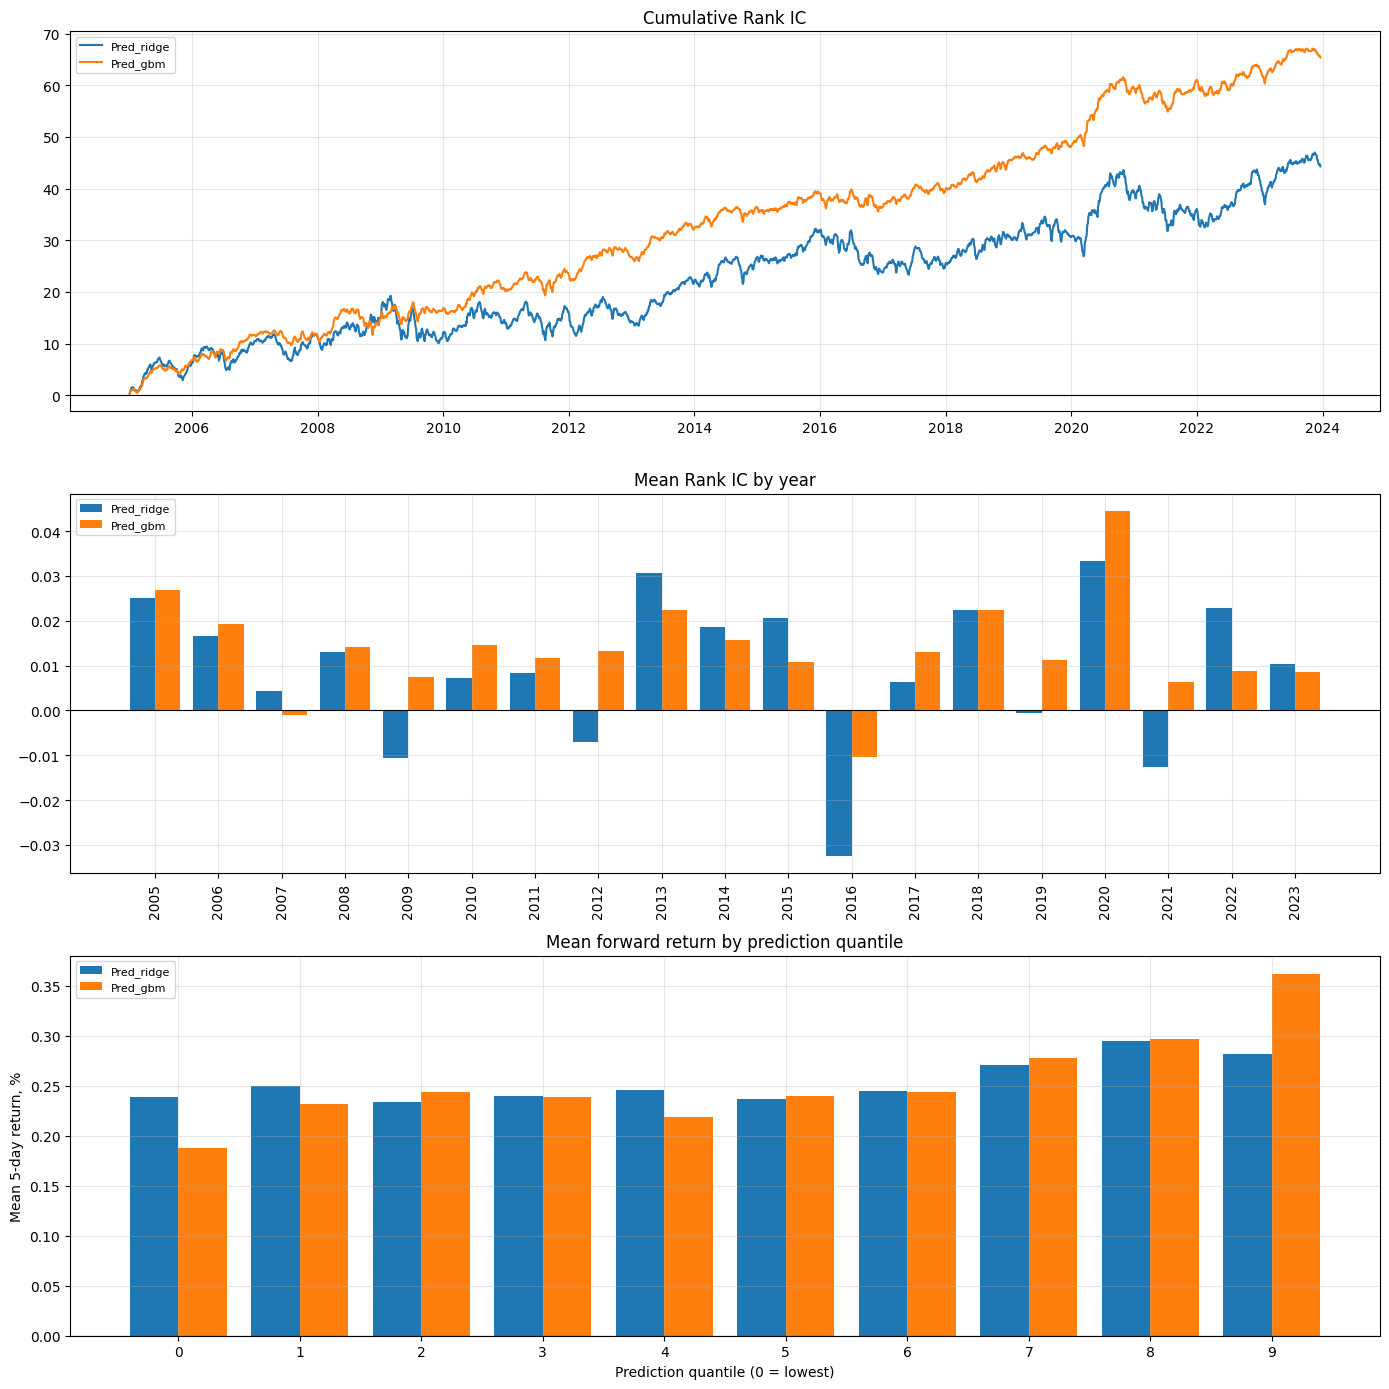

In [20]:
fig = plot_evaluation(results)

## Optuna

## Final Model Estimation on the Holdout Period